In [1]:
import pandas as pd
import numpy as np
import gzip
import matplotlib.pyplot as plt
import pickle
# from scipy.stats import linregress
import os
import sys
from datetime import date
# from sklearn.metrics import auc, f1_score
# import random
# from sklearn.decomposition import NMF, non_negative_factorization
import seaborn as sns
import time
from matplotlib.colors import LogNorm, Normalize
from mpl_toolkits.axes_grid1 import axes_grid

**Load data**

In [2]:
#read in 733 sample x 3.5+ million DHS presence/absence matrix
dhs = pd.read_table('/home/ctrader/Hold/DHS/dat_bin_FDR01_hg38.txt.gz', header=None).T
print(dhs.shape)
dhs_array = dhs.to_numpy()

(733, 3591898)


In [19]:
#Loading biosample embeddings
fn = gzip.GzipFile('/home/ctrader/Hold/DHS/2018-06-08NC16_NNDSVD_Basis.npy.gz', "r")
decomp_Basis = np.load(fn)
#Loading DHS embeddings
fn = gzip.GzipFile('/home/ctrader/Hold/DHS/2018-06-08NC16_NNDSVD_Mixture.npy.gz', "r")
decomp_Mixture = np.load(fn)
print(decomp_Mixture.shape)
print(decomp_Basis.shape)
n_biosamples, n_biosample_e = decomp_Basis.shape
n_DHS_e, n_DHSs = decomp_Mixture.shape
print(n_biosamples, n_DHSs)

(16, 3591898)
(733, 16)
733 3591898


In [20]:
del decomp_Mixture
del decomp_Basis

In [13]:
DHS_peak_signal_df = pd.read_csv('/home/ctrader/NMF_data/DHS_signal_matrix/DHS_peak_signal_hg38.75_20.normalized.GRCh38_no_alts_CT20220208.tsv', delimiter='\t')
DHS_peak_signal_array = DHS_peak_signal_df[DHS_peak_signal_df.columns[2:]].T.to_numpy()
DHS_peak_signal_array.shape
del DHS_peak_signal_df

/home/ctrader/.conda/envs/lightfm/lib/python3.8/site-packages/IPython/core/interactiveshell.py:3441: DtypeWarning: Columns (1) have mixed types.Specify dtype option on import or set low_memory=False.
  exec(code_obj, self.user_global_ns, self.user_ns)


(733, 3591898)

In [68]:
DHS_peak_signal_array_ave = np.mean(DHS_peak_signal_array, axis=0)

In [23]:
outfile = '/home/ctrader/NMF_data/DHS_signal_matrix/DHS_peak_signal_hg38.75_20.normalized.GRCh38_no_alts_array_CT20220215.npy'
np.save(outfile, DHS_peak_signal_array)

In [3]:
np_cycle_1_diff = np.load('/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/delta_fill_in_multiple_at_a_time_diffflat_sorteddiffflat_fillsize1000_cycle1_CT20220214.npz')
np_cycle_2_diff = np.load('/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/delta_fill_in_multiple_at_a_time_diffflat_sorteddiffflat_fillsize1000_cycle2_CT20220214.npz')
np_cycle_3_diff = np.load('/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/delta_fill_in_multiple_at_a_time_diffflat_sorteddiffflat_fillsize1000_cycle3_CT20220214.npz')

In [74]:
DHS_metadata = pd.read_table('/home/ctrader/Hold/DHS/DHS_Index_and_Vocabulary_hg38_WM20190703.txt.gz', header=None)

col_names = DHS_metadata.iloc[0]
DHS_metadata = DHS_metadata[1:]
DHS_metadata.columns = col_names
DHS_metadata = DHS_metadata.reset_index()
DHS_metadata[['identifier']] = DHS_metadata[['identifier']].astype(str)
DHS_metadata = DHS_metadata.drop(columns=['index'])
DHS_metadata['mean_signal'] = DHS_metadata['mean_signal'].astype(float)

/home/ctrader/.conda/envs/lightfm/lib/python3.8/site-packages/IPython/core/interactiveshell.py:3441: DtypeWarning: Columns (1,2,3,4,5,6,7,8) have mixed types.Specify dtype option on import or set low_memory=False.
  exec(code_obj, self.user_global_ns, self.user_ns)


In [86]:
#load the 0.01% call changes
pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_first_01_added_calls_delta_biosample_DHS_1_cycle_CT20220209.pickle', 'rb')
first_01_added_calls_delta_biosample_DHS=pickle.load(pickle_in)
pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_first_01_removed_calls_delta_biosample_DHS_1_cycle_CT20220209.pickle', 'rb')
first_01_removed_calls_delta_biosample_DHS=pickle.load(pickle_in)

first_01_added_calls_delta_vals = first_01_added_calls_delta_biosample_DHS[0, :]
first_01_added_calls_biosample_inds = first_01_added_calls_delta_biosample_DHS[1, :].astype(int)
first_01_added_calls_DHS_inds = first_01_added_calls_delta_biosample_DHS[2, :].astype(int)

first_01_removed_calls_delta_vals = first_01_removed_calls_delta_biosample_DHS[0, :]
first_01_removed_calls_biosample_inds = first_01_removed_calls_delta_biosample_DHS[1, :].astype(int)
first_01_removed_calls_DHS_inds = first_01_removed_calls_delta_biosample_DHS[2, :].astype(int)

**Comparing Delta values to peak signal**

In [12]:
#taking the first 1000 added/removed call delta values/ind
cycle_1_sorted_diff_flat = np_cycle_1_diff['sorted_diff_flat_array']
cycle_1_diff_flat = np_cycle_1_diff['diff_flat_array']

cycle_1_sorted_diff_flat_added = cycle_1_sorted_diff_flat[-1000:]
cycle_1_sorted_diff_flat_added = np.flip(cycle_1_sorted_diff_flat_added)
cycle_1_sorted_diff_flat_removed = cycle_1_sorted_diff_flat[:1000]
del cycle_1_sorted_diff_flat
cycle_1_diff_flat_added = cycle_1_diff_flat[cycle_1_sorted_diff_flat_added]
cycle_1_diff_flat_removed = cycle_1_diff_flat[cycle_1_sorted_diff_flat_removed]
del cycle_1_diff_flat

cycle_2_sorted_diff_flat = np_cycle_2_diff['sorted_diff_flat_array']
cycle_2_diff_flat = np_cycle_2_diff['diff_flat_array']

cycle_2_sorted_diff_flat_added = cycle_2_sorted_diff_flat[-1000:]
cycle_2_sorted_diff_flat_added = np.flip(cycle_2_sorted_diff_flat_added)
cycle_2_sorted_diff_flat_removed = cycle_2_sorted_diff_flat[:1000]
del cycle_2_sorted_diff_flat
cycle_2_diff_flat_added = cycle_2_diff_flat[cycle_2_sorted_diff_flat_added]
cycle_2_diff_flat_removed = cycle_2_diff_flat[cycle_2_sorted_diff_flat_removed]
del cycle_2_diff_flat

cycle_3_sorted_diff_flat = np_cycle_3_diff['sorted_diff_flat_array']
cycle_3_diff_flat = np_cycle_3_diff['diff_flat_array']

cycle_3_sorted_diff_flat_added = cycle_3_sorted_diff_flat[-1000:]
cycle_3_sorted_diff_flat_added = np.flip(cycle_3_sorted_diff_flat_added)
cycle_3_sorted_diff_flat_removed = cycle_3_sorted_diff_flat[:1000]
del cycle_3_sorted_diff_flat
cycle_3_diff_flat_added = cycle_3_diff_flat[cycle_3_sorted_diff_flat_added]
cycle_3_diff_flat_removed = cycle_3_diff_flat[cycle_3_sorted_diff_flat_removed]
del cycle_3_diff_flat

In [15]:
outfile = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/delta_fill_in_multiple_at_a_time_diffflat_sorteddiffflat_first_1000_added_removed_fillsize1000_cycle1_CT20220214.npz'
np.savez(outfile, cycle_1_sorted_diff_flat_added=cycle_1_sorted_diff_flat_added,
        cycle_1_sorted_diff_flat_removed=cycle_1_sorted_diff_flat_removed,
        cycle_1_diff_flat_added=cycle_1_diff_flat_added,
        cycle_1_diff_flat_removed=cycle_1_diff_flat_removed)

outfile = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/delta_fill_in_multiple_at_a_time_diffflat_sorteddiffflat_first_1000_added_removed_fillsize1000_cycle2_CT20220214.npz'
np.savez(outfile, cycle_2_sorted_diff_flat_added=cycle_2_sorted_diff_flat_added,
        cycle_2_sorted_diff_flat_removed=cycle_2_sorted_diff_flat_removed,
        cycle_2_diff_flat_added=cycle_2_diff_flat_added,
        cycle_2_diff_flat_removed=cycle_2_diff_flat_removed)

outfile = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/delta_fill_in_multiple_at_a_time_diffflat_sorteddiffflat_first_1000_added_removed_fillsize1000_cycle3_CT20220214.npz'
np.savez(outfile, cycle_3_sorted_diff_flat_added=cycle_3_sorted_diff_flat_added,
        cycle_3_sorted_diff_flat_removed=cycle_3_sorted_diff_flat_removed,
        cycle_3_diff_flat_added=cycle_3_diff_flat_added,
        cycle_3_diff_flat_removed=cycle_3_diff_flat_removed)

In [21]:
cycle_1_added_biosample_inds = cycle_1_sorted_diff_flat_added//n_DHSs
cycle_1_added_DHS_inds = cycle_1_sorted_diff_flat_added%n_DHSs

cycle_2_added_biosample_inds = cycle_2_sorted_diff_flat_added//n_DHSs
cycle_2_added_DHS_inds = cycle_2_sorted_diff_flat_added%n_DHSs

cycle_3_added_biosample_inds = cycle_3_sorted_diff_flat_added//n_DHSs
cycle_3_added_DHS_inds = cycle_3_sorted_diff_flat_added%n_DHSs

In [48]:
cycle_1_removed_biosample_inds = cycle_1_sorted_diff_flat_removed//n_DHSs
cycle_1_removed_DHS_inds = cycle_1_sorted_diff_flat_removed%n_DHSs

cycle_2_removed_biosample_inds = cycle_2_sorted_diff_flat_removed//n_DHSs
cycle_2_removed_DHS_inds = cycle_2_sorted_diff_flat_removed%n_DHSs

cycle_3_removed_biosample_inds = cycle_3_sorted_diff_flat_removed//n_DHSs
cycle_3_removed_DHS_inds = cycle_3_sorted_diff_flat_removed%n_DHSs

In [47]:
#peak signal values of added calls
cycle_1_added_peak_signal = []
for i, j in zip(cycle_1_added_biosample_inds, cycle_1_added_DHS_inds):
    cycle_1_added_peak_signal.append(DHS_peak_signal_array[i, j])
cycle_1_added_peak_signal = np.array(cycle_1_added_peak_signal)

cycle_2_added_peak_signal = []
for i, j in zip(cycle_2_added_biosample_inds, cycle_2_added_DHS_inds):
    cycle_2_added_peak_signal.append(DHS_peak_signal_array[i, j])
cycle_2_added_peak_signal = np.array(cycle_2_added_peak_signal)

cycle_3_added_peak_signal = []
for i, j in zip(cycle_3_added_biosample_inds, cycle_3_added_DHS_inds):
    cycle_3_added_peak_signal.append(DHS_peak_signal_array[i, j])
cycle_3_added_peak_signal = np.array(cycle_3_added_peak_signal)

#peak signal values of removed calls
cycle_1_removed_peak_signal = []
for i, j in zip(cycle_1_removed_biosample_inds, cycle_1_removed_DHS_inds):
    cycle_1_removed_peak_signal.append(DHS_peak_signal_array[i, j])
cycle_1_removed_peak_signal = np.array(cycle_1_removed_peak_signal)

cycle_2_removed_peak_signal = []
for i, j in zip(cycle_2_removed_biosample_inds, cycle_2_removed_DHS_inds):
    cycle_2_removed_peak_signal.append(DHS_peak_signal_array[i, j])
cycle_2_removed_peak_signal = np.array(cycle_2_removed_peak_signal)

cycle_3_removed_peak_signal = []
for i, j in zip(cycle_3_removed_biosample_inds, cycle_3_removed_DHS_inds):
    cycle_3_removed_peak_signal.append(DHS_peak_signal_array[i, j])
cycle_3_removed_peak_signal = np.array(cycle_3_removed_peak_signal)

Text(0.5, 1.06, 'Comparing Delta Values to DHS Peak Signal for Added Calls\nDelta Fill-in, Fill Size=1000 Calls')

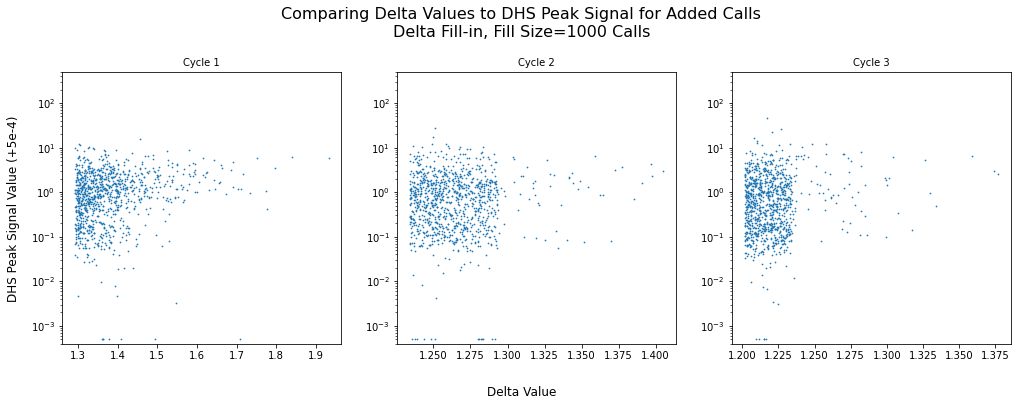

In [64]:
data = [cycle_1_diff_flat_added, 
        cycle_1_added_peak_signal+0.0005, 
        cycle_2_diff_flat_added, 
        cycle_2_added_peak_signal+0.0005, 
        cycle_3_diff_flat_added, 
        cycle_3_added_peak_signal+0.0005]

plot_titles = ['Cycle 1', 'Cycle 2', 'Cycle 3']

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(17,5))
fig.patch.set_facecolor('white')

axes = axes.ravel()
for ax, ind in zip(axes, range(3)):
    scat = ax.scatter(data[2*ind], data[(2*ind)+1], s=0.5)
    ax.set_title(plot_titles[ind], fontsize=10)
#     ax.set_xlim([0.001, 200])
    ax.set_ylim([0.0004, 500])
    ax.set_yscale('log')
#     ax.set_yscale('symlog')


fig.text(0.5, -0.02, 'Delta Value', ha='center', fontsize=12)
fig.text(0.08, 0.5, 'DHS Peak Signal Value (+5e-4)', va='center', rotation='vertical', fontsize=12)
plt.suptitle('Comparing Delta Values to DHS Peak Signal for Added Calls\nDelta Fill-in, Fill Size=1000 Calls', fontsize=16, x=0.5, y=1.06)

Text(0.5, 1.06, 'Comparing Delta Values to DHS Peak Signal for Removed Calls\nDelta Fill-in, Fill Size=1000 Calls')

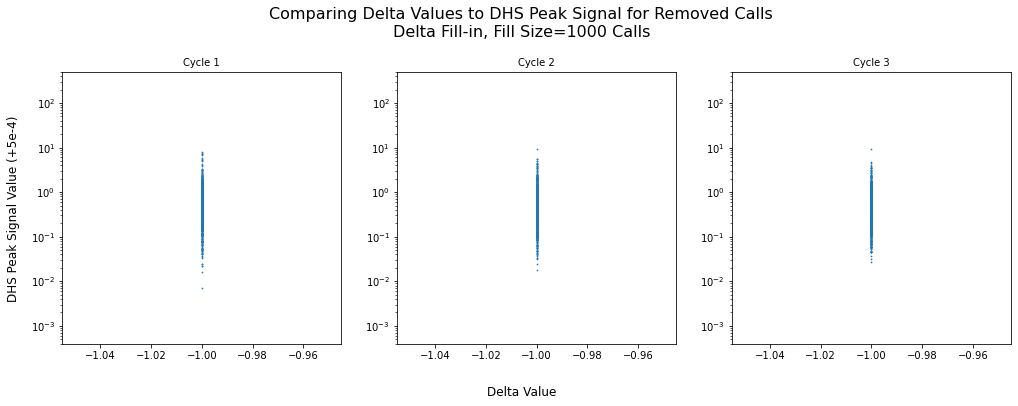

In [66]:
data = [cycle_1_diff_flat_removed, 
        cycle_1_removed_peak_signal+0.0005, 
        cycle_2_diff_flat_removed, 
        cycle_2_removed_peak_signal+0.0005, 
        cycle_3_diff_flat_removed, 
        cycle_3_removed_peak_signal+0.0005]

plot_titles = ['Cycle 1', 'Cycle 2', 'Cycle 3']

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(17,5))
fig.patch.set_facecolor('white')

axes = axes.ravel()
for ax, ind in zip(axes, range(3)):
    scat = ax.scatter(data[2*ind], data[(2*ind)+1], s=0.5)
    ax.set_title(plot_titles[ind], fontsize=10)
#     ax.set_xlim([0.001, 200])
    ax.set_ylim([0.0004, 500])
    ax.set_yscale('log')
#     ax.set_yscale('log')


fig.text(0.5, -0.02, 'Delta Value', ha='center', fontsize=12)
fig.text(0.08, 0.5, 'DHS Peak Signal Value (+5e-4)', va='center', rotation='vertical', fontsize=12)
plt.suptitle('Comparing Delta Values to DHS Peak Signal for Removed Calls\nDelta Fill-in, Fill Size=1000 Calls', fontsize=16, x=0.5, y=1.06)

In [72]:
cycle_1_added_DHS_mean_peak_signal = DHS_peak_signal_array_ave[cycle_1_added_DHS_inds]
cycle_2_added_DHS_mean_peak_signal = DHS_peak_signal_array_ave[cycle_2_added_DHS_inds]
cycle_3_added_DHS_mean_peak_signal = DHS_peak_signal_array_ave[cycle_3_added_DHS_inds]

cycle_1_removed_DHS_mean_peak_signal = DHS_peak_signal_array_ave[cycle_1_removed_DHS_inds]
cycle_2_removed_DHS_mean_peak_signal = DHS_peak_signal_array_ave[cycle_2_removed_DHS_inds]
cycle_3_removed_DHS_mean_peak_signal = DHS_peak_signal_array_ave[cycle_3_removed_DHS_inds]

Text(0.5, 1.06, 'Comparing DHS Peak Signal for Added and Removed Calls to Mean Peak Signal of Corresponding DHS\nDelta Fill-in, Fill Size=1000 Calls')

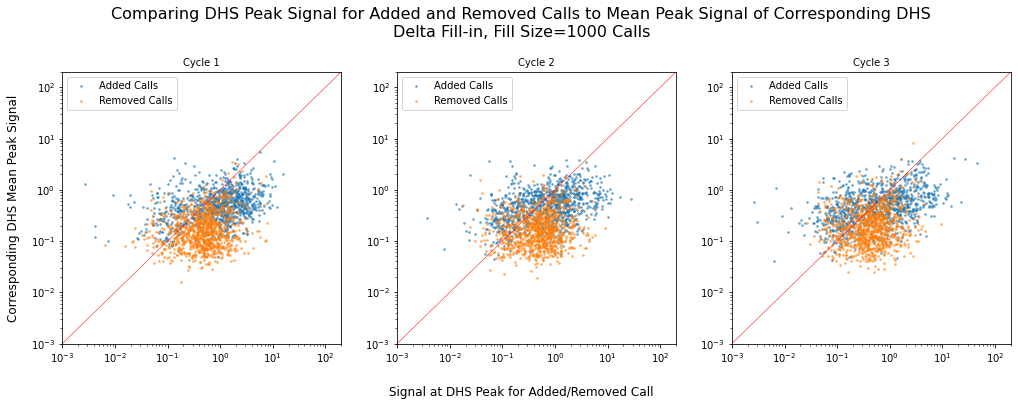

In [85]:
data = [cycle_1_added_peak_signal, 
        cycle_1_added_DHS_mean_peak_signal,
        cycle_1_removed_peak_signal,
        cycle_1_removed_DHS_mean_peak_signal,
        cycle_2_added_peak_signal, 
        cycle_2_added_DHS_mean_peak_signal,
        cycle_2_removed_peak_signal,
        cycle_2_removed_DHS_mean_peak_signal,
        cycle_3_added_peak_signal, 
        cycle_3_added_DHS_mean_peak_signal,
        cycle_3_removed_peak_signal,
        cycle_3_removed_DHS_mean_peak_signal]

plot_titles = ['Cycle 1', 'Cycle 2', 'Cycle 3']

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(17,5))
fig.patch.set_facecolor('white')

axes = axes.ravel()
for ax, ind in zip(axes, range(3)):
    scat = ax.scatter(data[4*ind], data[(4*ind)+1], s=3, alpha=0.5)
    scat = ax.scatter(data[(4*ind)+2], data[(4*ind)+3], s=3, alpha=0.5)
    ax.set_title(plot_titles[ind], fontsize=10)
    ax.set_xlim([0.001, 200])
    ax.set_ylim([0.001, 200])
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.legend(['Added Calls', 'Removed Calls'])
    ax.plot(np.arange(300)-1, np.arange(300)-1, c='r', linewidth=0.5)
    
# plt.legend(['First 1000 removed Calls', 'Last 1000 removed Calls'])
fig.text(0.5, -0.02, 'Signal at DHS Peak for Added/Removed Call', ha='center', fontsize=12)
fig.text(0.08, 0.5, 'Corresponding DHS Mean Peak Signal', va='center', rotation='vertical', fontsize=12)
plt.suptitle('Comparing DHS Peak Signal for Added and Removed Calls to Mean Peak Signal of Corresponding DHS\nDelta Fill-in, Fill Size=1000 Calls', fontsize=16, x=0.5, y=1.06)

In [75]:
#finding average signal value of added and removed calls
cycle_1_added_DHS_mean_signal = np.array(DHS_metadata.loc[cycle_1_added_DHS_inds]['mean_signal'])
cycle_2_added_DHS_mean_signal = np.array(DHS_metadata.loc[cycle_2_added_DHS_inds]['mean_signal'])
cycle_3_added_DHS_mean_signal = np.array(DHS_metadata.loc[cycle_3_added_DHS_inds]['mean_signal'])

cycle_1_removed_DHS_mean_signal = np.array(DHS_metadata.loc[cycle_1_removed_DHS_inds]['mean_signal'])
cycle_2_removed_DHS_mean_signal = np.array(DHS_metadata.loc[cycle_2_removed_DHS_inds]['mean_signal'])
cycle_3_removed_DHS_mean_signal = np.array(DHS_metadata.loc[cycle_3_removed_DHS_inds]['mean_signal'])

Text(0.5, 1.06, 'Comparing DHS Peak Signal for Added and Removed Calls to Mean Signal of Corresponding DHS\nDelta Fill-in, Fill Size=1000 Calls')

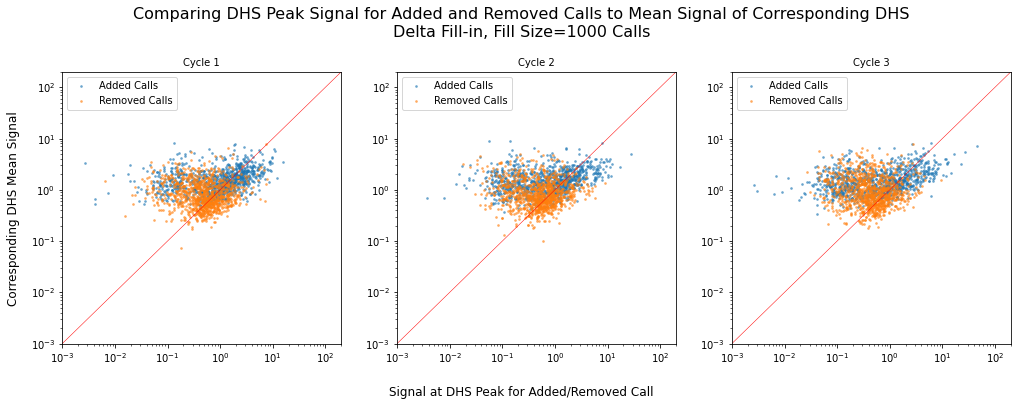

In [84]:
data = [cycle_1_added_peak_signal, 
        cycle_1_added_DHS_mean_signal,
        cycle_1_removed_peak_signal,
        cycle_1_removed_DHS_mean_signal,
        cycle_2_added_peak_signal, 
        cycle_2_added_DHS_mean_signal,
        cycle_2_removed_peak_signal,
        cycle_2_removed_DHS_mean_signal,
        cycle_3_added_peak_signal, 
        cycle_3_added_DHS_mean_signal,
        cycle_3_removed_peak_signal,
        cycle_3_removed_DHS_mean_signal]

plot_titles = ['Cycle 1', 'Cycle 2', 'Cycle 3']

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(17,5))
fig.patch.set_facecolor('white')

axes = axes.ravel()
for ax, ind in zip(axes, range(3)):
    scat = ax.scatter(data[4*ind], data[(4*ind)+1], s=3, alpha=0.5)
    scat = ax.scatter(data[(4*ind)+2], data[(4*ind)+3], s=3, alpha=0.5)
    ax.set_title(plot_titles[ind], fontsize=10)
    ax.set_xlim([0.001, 200])
    ax.set_ylim([0.001, 200])
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.legend(['Added Calls', 'Removed Calls'])
    ax.plot(np.arange(300)-1, np.arange(300)-1, c='r', linewidth=0.5)
    
# plt.legend(['First 1000 removed Calls', 'Last 1000 removed Calls'])
fig.text(0.5, -0.02, 'Signal at DHS Peak for Added/Removed Call', ha='center', fontsize=12)
fig.text(0.08, 0.5, 'Corresponding DHS Mean Signal', va='center', rotation='vertical', fontsize=12)
plt.suptitle('Comparing DHS Peak Signal for Added and Removed Calls to Mean Signal of Corresponding DHS\nDelta Fill-in, Fill Size=1000 Calls', fontsize=16, x=0.5, y=1.06)

In [93]:
#finding total inds of 0.01% method and 1000 method
first_01_added_calls_total_inds = (first_01_added_calls_biosample_inds * n_DHSs) + first_01_added_calls_DHS_inds
first_01_removed_calls_total_inds = (first_01_removed_calls_biosample_inds * n_DHSs) + first_01_removed_calls_DHS_inds

cycle_1_added_total_inds = (cycle_1_added_biosample_inds * n_DHSs) + cycle_1_added_DHS_inds
cycle_1_removed_total_inds = (cycle_1_removed_biosample_inds * n_DHSs) + cycle_1_removed_DHS_inds

cycle_2_added_total_inds = (cycle_2_added_biosample_inds * n_DHSs) + cycle_2_added_DHS_inds
cycle_2_removed_total_inds = (cycle_2_removed_biosample_inds * n_DHSs) + cycle_2_removed_DHS_inds

cycle_3_added_total_inds = (cycle_3_added_biosample_inds * n_DHSs) + cycle_3_added_DHS_inds
cycle_3_removed_total_inds = (cycle_3_removed_biosample_inds * n_DHSs) + cycle_3_removed_DHS_inds

In [140]:
cycle_1_added_total_ind_in_01 = []
for i in cycle_1_added_total_inds:
    ind_01 = np.where(first_01_added_calls_total_inds==i)[0]
    cycle_1_added_total_ind_in_01.append(ind_01[0])
cycle_1_added_total_ind_in_01 = np.array(cycle_1_added_total_ind_in_01)

cycle_2_added_total_ind_in_01 = []
for i in cycle_2_added_total_inds:
    ind_01 = np.where(first_01_added_calls_total_inds==i)[0]
    cycle_2_added_total_ind_in_01.append(ind_01[0])
cycle_2_added_total_ind_in_01 = np.array(cycle_2_added_total_ind_in_01)

cycle_3_added_total_ind_in_01 = []
for i in cycle_3_added_total_inds:
    ind_01 = np.where(first_01_added_calls_total_inds==i)[0]
    cycle_3_added_total_ind_in_01.append(ind_01[0])
cycle_3_added_total_ind_in_01 = np.array(cycle_3_added_total_ind_in_01)

In [141]:
cycle_1_removed_total_ind_in_01 = []
for i in cycle_1_removed_total_inds:
    ind_01 = np.where(first_01_removed_calls_total_inds==i)[0]
    cycle_1_removed_total_ind_in_01.append(ind_01[0])
cycle_1_removed_total_ind_in_01 = np.array(cycle_1_removed_total_ind_in_01)

cycle_2_removed_total_ind_in_01 = []
for i in cycle_2_removed_total_inds:
    ind_01 = np.where(first_01_removed_calls_total_inds==i)[0]
    cycle_2_removed_total_ind_in_01.append(ind_01[0])
cycle_2_removed_total_ind_in_01 = np.array(cycle_2_removed_total_ind_in_01)

cycle_3_removed_total_ind_in_01 = []
for i in cycle_3_removed_total_inds:
    ind_01 = np.where(first_01_removed_calls_total_inds==i)[0]
    cycle_3_removed_total_ind_in_01.append(ind_01[0])
cycle_3_removed_total_ind_in_01 = np.array(cycle_3_removed_total_ind_in_01)

Text(0.5, 1.0, 'Comparing Order in which Calls are Added with Delta Fill In\n1000 at a Time Method vs. Fill Size=0.01%, Cycle 1')

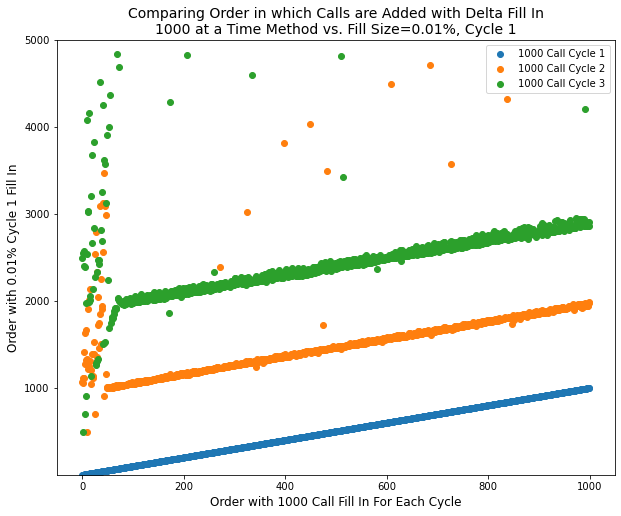

In [142]:
fig = plt.figure(figsize=(10,8))
fig.patch.set_facecolor('white')

plt.scatter(np.arange(1000), cycle_1_added_total_ind_in_01)
plt.scatter(np.arange(1000), cycle_2_added_total_ind_in_01)
plt.scatter(np.arange(1000), cycle_3_added_total_ind_in_01)
plt.ylim([1, 5000])

plt.xlabel('Order with 1000 Call Fill In For Each Cycle', fontsize=12)
plt.ylabel('Order with 0.01% Cycle 1 Fill In', fontsize=12)
plt.legend(['1000 Call Cycle 1', '1000 Call Cycle 2', '1000 Call Cycle 3'])
plt.title('Comparing Order in which Calls are Added with Delta Fill In\n1000 at a Time Method vs. Fill Size=0.01%, Cycle 1', fontsize=14)

Text(0.5, 1.0, 'Comparing Order in which Calls are Removed with Delta Fill In\n1000 at a Time Method vs. Fill Size=0.01%, Cycle 1')

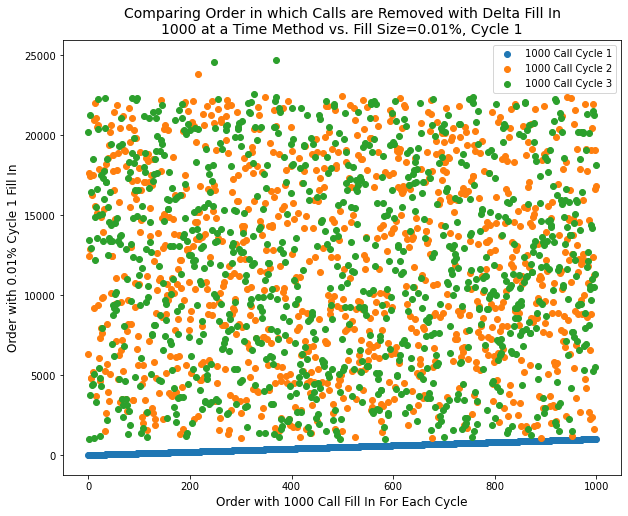

In [145]:
fig = plt.figure(figsize=(10,8))
fig.patch.set_facecolor('white')

plt.scatter(np.arange(1000), cycle_1_removed_total_ind_in_01)
plt.scatter(np.arange(1000), cycle_2_removed_total_ind_in_01)
plt.scatter(np.arange(1000), cycle_3_removed_total_ind_in_01)
# plt.ylim([1, 5000])

plt.xlabel('Order with 1000 Call Fill In For Each Cycle', fontsize=12)
plt.ylabel('Order with 0.01% Cycle 1 Fill In', fontsize=12)
plt.legend(['1000 Call Cycle 1', '1000 Call Cycle 2', '1000 Call Cycle 3'])
plt.title('Comparing Order in which Calls are Removed with Delta Fill In\n1000 at a Time Method vs. Fill Size=0.01%, Cycle 1', fontsize=14)

In [148]:
cycle_3_diff_flat_added - first_01_added_calls_delta_vals[2000:3000]

array([0.14536059, 0.14240884, 0.12737916, 0.10265762, 0.09845892,
       0.095144  , 0.08645765, 0.07654865, 0.07277268, 0.07008144,
       0.06900057, 0.06857873, 0.06850946, 0.06763523, 0.05556431,
       0.05427325, 0.05420859, 0.05154904, 0.05142863, 0.0511958 ,
       0.05061616, 0.04917914, 0.04747566, 0.04514687, 0.04472776,
       0.04374832, 0.04317836, 0.04290028, 0.04239299, 0.04165344,
       0.04026878, 0.04033037, 0.03964852, 0.0395862 , 0.03867423,
       0.03600212, 0.03456667, 0.0325119 , 0.03111302, 0.03091514,
       0.03043408, 0.0293695 , 0.0280129 , 0.02774675, 0.02730531,
       0.02715247, 0.02712341, 0.02578544, 0.02462002, 0.02378132,
       0.02297168, 0.02219709, 0.0208703 , 0.01875212, 0.01778389,
       0.01641086, 0.01568001, 0.01556166, 0.01325347, 0.0123203 ,
       0.01221209, 0.01111765, 0.01109852, 0.00937324, 0.00800301,
       0.0077982 , 0.00782544, 0.00781001, 0.0077735 , 0.00746755,
       0.00744535, 0.00721712, 0.00722249, 0.00645301, 0.00644